# Assignment 1: K-Means Limitations Report
**Name:** Gajendra
**Roll No:** 2301ME18


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering

import warnings
warnings.filterwarnings('ignore')

### 1. Unbalance Dataset
**Failure Mode:** Differing cluster sizes
N=6500 points, k=8 Gaussian clusters of very unequal sizes.

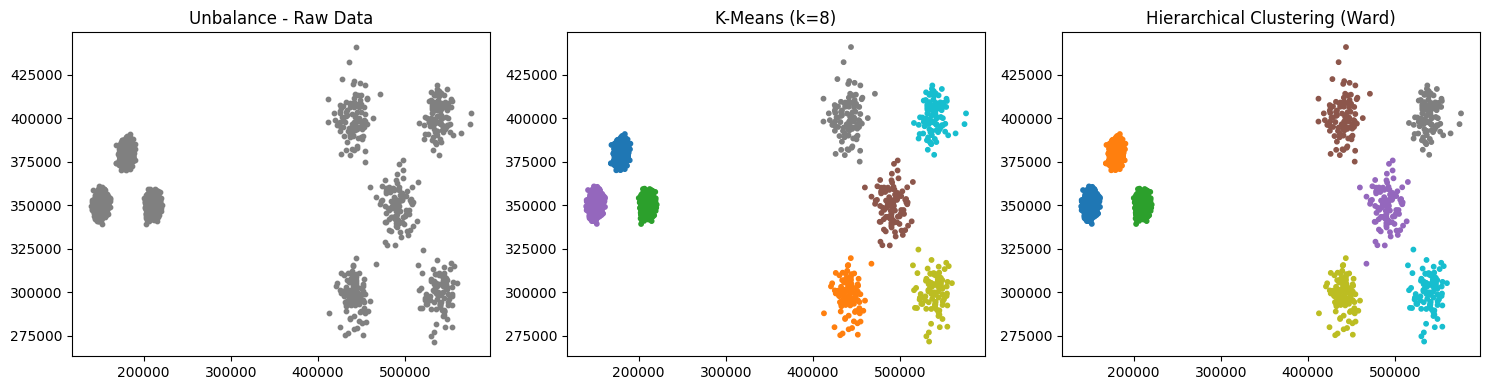

In [3]:
# Load dataset
url_unbalance = "https://cs.joensuu.fi/sipu/datasets/unbalance.txt"
df_unbalance = pd.read_csv(url_unbalance, sep=r'\s+', header=None)
X_unb = df_unbalance.iloc[:, :2].values

# Plot Raw Data
plt.figure(figsize=(15, 4))
plt.subplot(1, 3, 1)
plt.scatter(X_unb[:, 0], X_unb[:, 1], s=10, color='gray')
plt.title("Unbalance - Raw Data")

# K-Means
kmeans_unb = KMeans(n_clusters=8, random_state=42)
labels_km_unb = kmeans_unb.fit_predict(X_unb)
plt.subplot(1, 3, 2)
plt.scatter(X_unb[:, 0], X_unb[:, 1], c=labels_km_unb, cmap='tab10', s=10)
plt.title("K-Means (k=8)")

# Hierarchical Clustering
hc_unb = AgglomerativeClustering(n_clusters=8, linkage='ward')
labels_hc_unb = hc_unb.fit_predict(X_unb)
plt.subplot(1, 3, 3)
plt.scatter(X_unb[:, 0], X_unb[:, 1], c=labels_hc_unb, cmap='tab10', s=10)
plt.title("Hierarchical Clustering (Ward)")

plt.tight_layout()
plt.show()

**Observation:**
K-Means fails here because it tends to produce clusters of relatively uniform size. When faced with clusters of vastly different sizes, K-Means splits the larger clusters and absorbs smaller ones to minimize within-cluster variance. In contrast, Hierarchical Clustering (with Ward linkage) can successfully isolate the different-sized clusters better, though density-based methods are also excellent for this scenario.

### 2. Jain Dataset
**Failure Mode:** Differing densities
N=373 points, k=2 crescent-shaped clusters of different density.

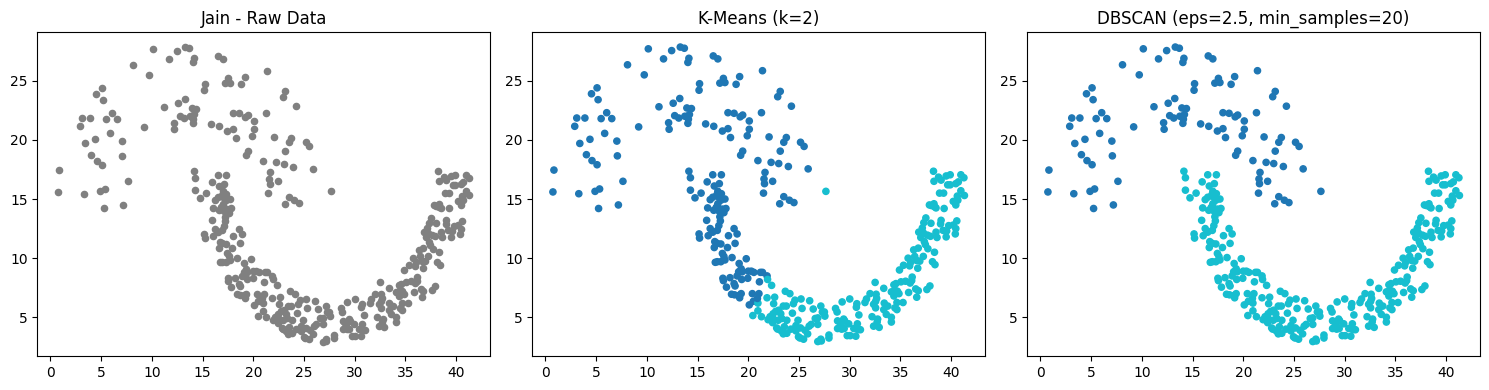

In [10]:
# Load dataset
url_jain = "https://cs.joensuu.fi/sipu/datasets/jain.txt"
df_jain = pd.read_csv(url_jain, sep=r'\s+', header=None)
X_jain = df_jain.iloc[:, :2].values

# Plot Raw Data
plt.figure(figsize=(15,4))
plt.subplot(1, 3, 1)
plt.scatter(X_jain[:, 0], X_jain[:, 1], s=20, color='gray')
plt.title("Jain - Raw Data")

# K-Means
kmeans_jain = KMeans(n_clusters=2, random_state=42)
labels_km_jain = kmeans_jain.fit_predict(X_jain)
plt.subplot(1, 3, 2)
plt.scatter(X_jain[:, 0], X_jain[:, 1], c=labels_km_jain, cmap='tab10', s=20)
plt.title("K-Means (k=2)")

# DBSCAN
dbscan_jain = DBSCAN(eps=2.5, min_samples=20)
labels_db_jain = dbscan_jain.fit_predict(X_jain)
plt.subplot(1, 3, 3)
plt.scatter(X_jain[:, 0], X_jain[:, 1], c=labels_db_jain, cmap='tab10', s=20)
plt.title("DBSCAN (eps=2.5, min_samples=20)")

plt.tight_layout()
plt.show()

**Observation:**
K-Means assumes that clusters have similar densities and are roughly spherical, which causes it to split the larger, less dense crescent and merge parts of it with the denser crescent. DBSCAN successfully clusters this dataset because it groups points based on continuous regions of high density, easily adapting to the varied density and non-globular shape.

### 3. Spiral Dataset
**Failure Mode:** Non-globular shape
N=312 points, k=3 interleaved spiral-shaped clusters.

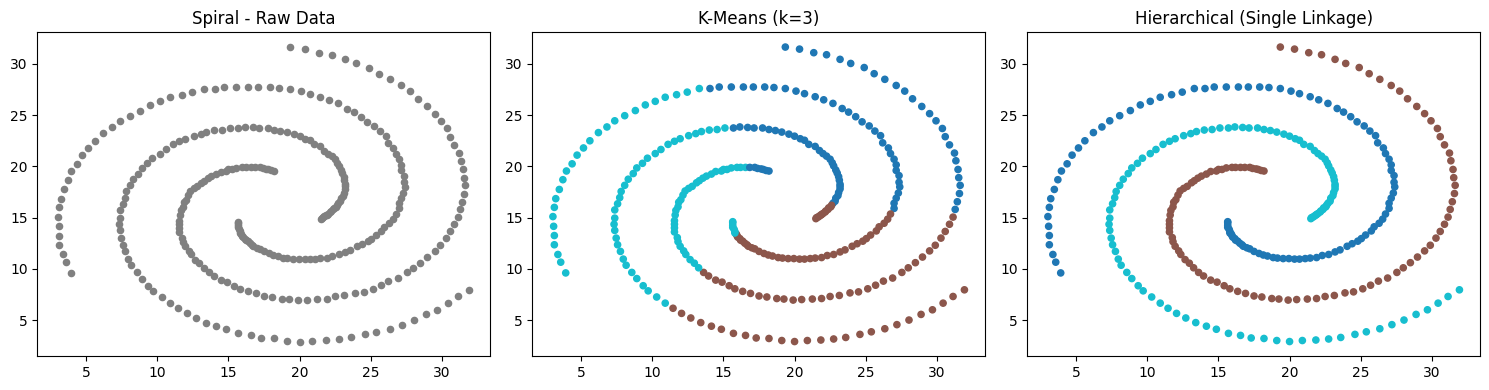

In [ ]:
# Load dataset
url_spiral = "https://cs.joensuu.fi/sipu/datasets/spiral.txt"
df_spiral = pd.read_csv(url_spiral, sep=r'\s+', header=None)
X_spiral = df_spiral.iloc[:, :2].values

# Plot Raw Data
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.scatter(X_spiral[:, 0], X_spiral[:, 1], s=20, color='gray')
plt.title("Spiral - Raw Data")

# K-Means
kmeans_spiral = KMeans(n_clusters=3, random_state=42)
labels_km_spiral = kmeans_spiral.fit_predict(X_spiral)
plt.subplot(1, 3, 2)
plt.scatter(X_spiral[:, 0], X_spiral[:, 1], c=labels_km_spiral, cmap='tab10', s=20)
plt.title("K-Means (k=3)")

# Hierarchical Clustering (Single Linkage)
hc_spiral = AgglomerativeClustering(n_clusters=3, linkage='single')
labels_hc_spiral = hc_spiral.fit_predict(X_spiral)
plt.subplot(1, 3, 3)
plt.scatter(X_spiral[:, 0], X_spiral[:, 1], c=labels_hc_spiral, cmap='tab10', s=20)
plt.title("Hierarchical (Single Linkage)")

plt.tight_layout()
plt.show()

**Observation:**
K-Means strictly partitions space into Voronoi cells (assuming spherical, convex shapes), meaning it cannot follow the contiguous curves of the interleaved spirals. Hierarchical clustering using single linkage groups points by their nearest neighbors, allowing it to seamlessly follow the non-globular, chaining structure of the spirals and correctly segment them.